# Plot a figure displaying our 3 different hypotheses

In [ ]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import warnings
import pandas as pd
import json

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

Linear / lDDM: gradual   MetaScore = -1.00e-02 (category 0, x = -0.00)
Non-linear: bistable     MetaScore = -2.28e-05 (category 1, x = 1.49)
Non-linear: metastable   MetaScore = -2.04e-06 (category 3, x = 1.20)


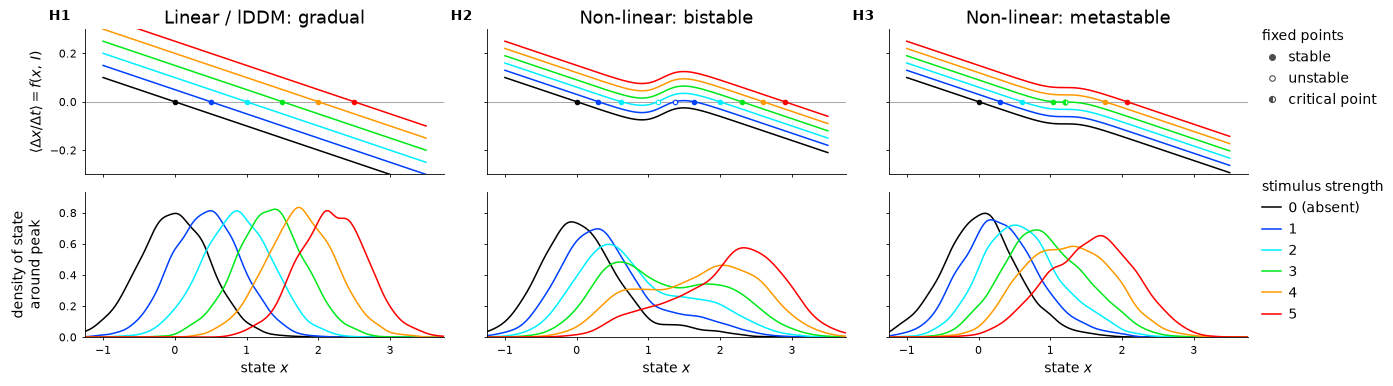

In [20]:
import matplotlib as mpl
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde


OUT = Path("fig_linear_bistable_metastable")
SEED = 42
N_TRIALS = 5000
BASELINE_STEPS = 100
STIM_STEPS = 25
AVG_STEPS = 10

CATEGORIES = list(range(6))
TAU = 10
PROCESS_NOISE = 0.25
MEASURE_NOISE = 0.1
THRESHOLD = 1.2
SHARPNESS = 7
W_LINEAR = {f"w{k}": 0.05 * k for k in CATEGORIES}
W_NONLINEAR = {f"w{k}": 0.03 * k for k in CATEGORIES}
GAIN_BISTABLE = 0.14
GAIN_METASTABLE = 4 / (SHARPNESS * TAU)  # critical gain: max slope of the sigmoid feedback = 1/tau

X_DRIFT = np.linspace(-1, 3.5, 2000)
X_KDE = np.linspace(-1.25, 3.75, 600)
XLIM = (-1.25, 3.75)
YLIM_DRIFT = (-0.3, 0.3)

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})


def build_models():
    common = dict(tau=TAU, process_noise=PROCESS_NOISE, measure_noise=MEASURE_NOISE)
    linear = lead.model.StratifiedLinear(**common, **W_LINEAR)
    bistable = lead.model.StratifiedNonLinear1(**common, gain=GAIN_BISTABLE, threshold=THRESHOLD,
                                               sharpness=SHARPNESS, **W_NONLINEAR)
    metastable = lead.model.StratifiedNonLinear1(**common, gain=GAIN_METASTABLE, threshold=THRESHOLD,
                                                 sharpness=SHARPNESS, **W_NONLINEAR)
    return [
        dict(title="Linear / lDDM: gradual", model=linear, vline=THRESHOLD, vlabel="threshold"),
        dict(title="Non-linear: bistable", model=bistable, vline=THRESHOLD, vlabel="threshold (implicit)"),
        dict(title="Non-linear: metastable", model=metastable, vline=None, vlabel="critical"),
    ]


def drift(model, x, cat):
    return model.core(x, np.ones_like(x), cat) - x


def equilibria(x, f):
    idx = np.where(np.diff(np.sign(f)) != 0)[0]
    out = []
    for i in idx:
        x0 = x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i])
        out.append((x0, f[i + 1] < f[i]))
    return out


def meta_score(x, f):
    fp = np.gradient(f, x)
    d = f ** 2 + fp ** 2
    i = np.argmin(d)
    return -d[i], x[i]


def simulate(model):
    one_input = np.concatenate((np.zeros(BASELINE_STEPS), np.ones(STIM_STEPS + 1)))
    inputs = {cat: np.tile(one_input, (N_TRIALS, 1)) for cat in CATEGORIES}
    sims = model.measure_simulations(input_series=inputs)
    return {cat: sims[cat][:, -AVG_STEPS:].mean(1) for cat in CATEGORIES}


np.random.seed(SEED)
panels = build_models()

for p in panels:
    scores = [meta_score(X_DRIFT, drift(p["model"], X_DRIFT, c)) for c in CATEGORIES]
    best = int(np.argmax([s[0] for s in scores]))
    p["meta"], p["ghost_x"], p["ghost_cat"] = scores[best][0], scores[best][1], best
    if p["vline"] is None:
        p["vline"] = p["ghost_x"]
    p["avgs"] = simulate(p["model"])
    print(f"{p['title']:<24s} MetaScore = {p['meta']:.2e} (category {best}, x = {p['ghost_x']:.2f})")

fig, axes = plt.subplots(2, 3, figsize=(15, 4.0), sharex=True,
                         gridspec_kw=dict(height_ratios=[1, 1], hspace=0.12, wspace=0.12))

for j, p in enumerate(panels):
    ax = axes[0, j]
    ax.axhline(0, color="0.6", lw=0.6, zorder=0)
    for cat in CATEGORIES:
        f = drift(p["model"], X_DRIFT, cat)
        color = lead.visual.colormap(cat)
        ax.plot(X_DRIFT, f, color=color, label=str(cat))
        for x0, stable in equilibria(X_DRIFT, f):
            if YLIM_DRIFT[0] < 0 < YLIM_DRIFT[1] and XLIM[0] < x0 < XLIM[1]:
                ax.plot(x0, 0, "o", ms=3.2, mew=0.8, mec=color,
                        mfc=color if stable else "white", zorder=4)
    if p["title"].endswith("metastable"):
        ax.plot(p["ghost_x"], 0, "o", ms=3.6, mew=0.8, mec=lead.visual.colormap(p["ghost_cat"]),
                mfc=lead.visual.colormap(p["ghost_cat"]), fillstyle="left",
                markerfacecoloralt="white", zorder=5)
    ax.set_ylim(*YLIM_DRIFT)
    ax.set_yticks([-0.2, 0, 0.2])
    ax.set_title(p["title"], pad=4)
    if j == 0:
        ax.set_ylabel(r"$\langle \Delta x / \Delta t \rangle = f(x,\,I)$")
    else:
        ax.tick_params(labelleft=False)

dens_max = 0
for j, p in enumerate(panels):
    ax = axes[1, j]
    for cat in CATEGORIES:
        d = gaussian_kde(p["avgs"][cat])(X_KDE)
        dens_max = max(dens_max, d.max())
        ax.plot(X_KDE, d, color=lead.visual.colormap(cat))
    ax.set_xlabel(r"state $x$")
    if j == 0:
        ax.set_ylabel("density of state\naround peak")
    else:
        ax.tick_params(labelleft=False)

for ax in axes[1]:
    ax.set_ylim(0, dens_max * 1.12)
for ax in axes.flat:
    ax.set_xlim(*XLIM)

for ax, label in zip(axes[0], ("H1", "H2", "H3")):
    ax.text(-0.04, 1.04, label, transform=ax.transAxes, fontsize=10, fontweight="bold",
            ha="right", va="bottom")

eq_handles = [
    Line2D([], [], ls="", marker="o", ms=4, mfc="0.3", mec="0.3", label="stable"),
    Line2D([], [], ls="", marker="o", ms=4, mfc="white", mec="0.3", mew=0.8, label="unstable"),
    Line2D([], [], ls="", marker="o", ms=4.4, mfc="0.3", mec="0.3", mew=0.8, fillstyle="left",
           markerfacecoloralt="white", label="critical point"),
]
stim_handles = [Line2D([], [], color=lead.visual.colormap(c), label=str(c)) for c in CATEGORIES]
stim_handles[0].set_label("0 (absent)")

legend_kw = dict(loc="upper left", frameon=False, alignment="left", borderaxespad=0,
                 borderpad=0, handlelength=1.4, handletextpad=0.5)
leg_eq = axes[0, 2].legend(handles=eq_handles, title="fixed points",
                           bbox_to_anchor=(1.04, 1.0), **legend_kw)
axes[0, 2].add_artist(leg_eq)

fig.canvas.draw()
bottom = axes[0, 2].transAxes.inverted().transform(
    leg_eq.get_window_extent(fig.canvas.get_renderer()))[0, 1]
axes[0, 2].legend(handles=stim_handles, title="stimulus strength",
                  bbox_to_anchor=(1.04, bottom - 0.5), **legend_kw)

fig.align_ylabels(axes[:, 0])
fig.savefig(OUT.with_suffix(".pdf"), bbox_inches="tight", pad_inches=0.02)
# fig.savefig(OUT.with_suffix(".svg"), bbox_inches="tight", pad_inches=0.02)
fig.savefig(OUT.with_suffix(".png"), dpi=600, bbox_inches="tight", pad_inches=0.02)
plt.show()